### Problem statement:

For a safe and secure lending experience, it's important to analyze the past data. In this project, you have to build a deep learning model to predict the chance of default for future loans using historical data. As you will see, this dataset is highly imbalanced and includes a lot of features that make this problem more challenging.

**Objective:** Create a model that predicts whether or not an applicant will be able to repay a loan using historical data

**Domain:** Finance

**Analysis to be done:** Perform data preprocessing and build a deep learning prediction model

**Dataset**: https://drive.google.com/drive/folders/1kwwdDkY5QYqpS_OwB7DOm1GJ7Mox92nb

### <u> Load the dataset that is given to you </u>

In [413]:
import numpy as np
import tensorflow as tf

RSEED = 42
tf.keras.utils.set_random_seed(RSEED)

This random seed will allow me to test on exactly the same random choices each time, including data splits and weight intialization.

In [414]:
import pandas as pd

df = pd.read_csv('loan_data.csv', index_col='SK_ID_CURR')

df.head()

,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
SK_ID_CURR,,,,,,,,,,,,,,,,,,,,,
100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,297000.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,513000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [415]:
print("Shape of the table:", df.shape)

Shape of the table: (307511, 121)



### <u> Check for null values in the dataset

In [416]:
pd.set_option('display.max_rows', 100)
missing = df.isnull().sum()

# Filter for columns missing at least 1
missing = missing[missing > 0].to_frame().rename(columns={0: 'Num missing'})  

# Add a percent column
missing['percent'] = missing['Num missing'] / len(df) * 100

# Put largest amounts on top
missing = missing.sort_values('Num missing', ascending=False)  

missing_many = (missing.percent >= 30).sum()

# Formatting
missing['Num missing'] = missing['Num missing'].map('{:,}'.format)
missing['percent'] = missing['percent'].map('{:,.0f}%'.format)

missing

,Num missing,percent
COMMONAREA_MEDI,"214,865",70%
COMMONAREA_AVG,"214,865",70%
COMMONAREA_MODE,"214,865",70%
NONLIVINGAPARTMENTS_MEDI,"213,514",69%
NONLIVINGAPARTMENTS_MODE,"213,514",69%
NONLIVINGAPARTMENTS_AVG,"213,514",69%
FONDKAPREMONT_MODE,"210,295",68%
LIVINGAPARTMENTS_MODE,"210,199",68%
LIVINGAPARTMENTS_MEDI,"210,199",68%
LIVINGAPARTMENTS_AVG,"210,199",68%


In [417]:
print(f"{missing_many} columns are missing at least 30% of their cells.")

rows, cols = df.shape
total_cells = rows * cols
missing_cells = df.isnull().sum().sum()
print(f"{missing_cells / total_cells * 100 :.2f}% of all cells are missing.")

50 columns are missing at least 30% of their cells.
24.60% of all cells are missing.


A majority of the columns with many missing values represent less directly predictive data about a customer, such as statistics of the housing complexes they live in or age of their assets. They mainly exist as backup data for when more directly relevant data is not available, such as credit score or salary. Since some of these columns are missing up to 70% of their data, dropping them could be an option, but this may reduce the predictive power for customers who only have this data available. A better option would be to create a "missing" column for each of these columns and let the neural network learn when to use them. I will create a missing column for each of these. Median imputation would be best here to not skew the average of the data and to not be easily affected by outliers.

For occupation, it has more predictive power, and the missing cells might be from unemployed customers or customers who have an informal income. I will impute missing data with "Unknown" for this one.

For "EXT_SOURCE_3", since lacking information from external sources may correlate with default risk, a missing column may help here too. Since we are feeding it into a neural network which requires numbers as input, it will still need to be imputed. The median would work well here because it wouldn't disrupt the average of this column which would result in smoother gradient descent calculations.

For the "AMT_REQ_CREDIT_BUREAU" columns, missing data likely means that the customer has never requested their credit score, so imputing with 0 would make sense.

For the last columns in the list with very little data missing, a standard median imputation can fill in the missing values with very little effect to accuracy.


### <u> Data preprocessing

In [418]:
display(df.DAYS_EMPLOYED.value_counts())
df["DAYS_EMPLOYED"] = df["DAYS_EMPLOYED"].replace(365243, np.nan)

DAYS_EMPLOYED
 365243    55374
-200         156
-224         152
-230         151
-199         151
           ...  
-13961         1
-11827         1
-10176         1
-9459          1
-8694          1
Name: count, Length: 12574, dtype: int64

This column represents total number of days the applicant has been employed. 365,243 days is over 1,000 years, so it has likely been used as a placeholder and should be fixed so it doesn't throw off the model.

In [419]:
# Feature engineer useful features
df["INCOME_CREDIT_PERC"] = df["AMT_INCOME_TOTAL"] / (df["AMT_CREDIT"] + 1e-5)
df["ANNUITY_INCOME_PERC"] = df["AMT_ANNUITY"] / (df["AMT_INCOME_TOTAL"] + 1e-5)
df["PAYMENT_RATE"] = df["AMT_ANNUITY"] / (df["AMT_CREDIT"] + 1e-5)
df["DAYS_EMPLOYED_PERC"] = df["DAYS_EMPLOYED"] / (df["DAYS_BIRTH"] + 1e-5)

These features are commonly used in the banking industry and may help the model predict better.

In [420]:
from sklearn.model_selection import train_test_split

X = df.drop(columns='TARGET')
y = df.TARGET

# Assign 20% of the data (stratified) to the test set
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=RSEED, stratify=y)

# Split the remaining 80% into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.2, random_state=RSEED, stratify=y_temp)

In [421]:
pd.set_option('display.max_info_columns', 200)
df.describe().loc[['min', 'max']]

,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,...,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,INCOME_CREDIT_PERC,ANNUITY_INCOME_PERC,PAYMENT_RATE,DAYS_EMPLOYED_PERC
min,0.0,0.0,25650.0,45000.0,1615.5,40500.0,0.000290,-25229.0,-17912.0,-24672.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.011801,0.000224,0.022073,-0.000000
max,1.0,19.0,117000000.0,4050000.0,258025.5,4050000.0,0.072508,-7489.0,0.0,0.0,...,4.0,9.0,8.0,27.0,261.0,25.0,208.003328,1.875965,0.124430,0.728811


This shows that the data needs to be scaled since we are feeding it into a neural network.

In [422]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

# Columns with many missing cells (47%+): add missing indicator column and impute with the median
median_impute_indicator_cols = [    
    'COMMONAREA_MEDI', 'COMMONAREA_AVG', 'COMMONAREA_MODE', 'NONLIVINGAPARTMENTS_MEDI', 'NONLIVINGAPARTMENTS_MODE', 'NONLIVINGAPARTMENTS_AVG', 
    'LIVINGAPARTMENTS_MODE', 'LIVINGAPARTMENTS_MEDI', 'LIVINGAPARTMENTS_AVG', 'FLOORSMIN_MODE', 'FLOORSMIN_MEDI', 'FLOORSMIN_AVG', 'YEARS_BUILD_MODE', 'YEARS_BUILD_MEDI', 
    'YEARS_BUILD_AVG', 'OWN_CAR_AGE', 'LANDAREA_AVG', 'LANDAREA_MEDI', 'LANDAREA_MODE', 'BASEMENTAREA_MEDI', 'BASEMENTAREA_AVG', 'BASEMENTAREA_MODE', 'EXT_SOURCE_1', 
    'NONLIVINGAREA_MEDI', 'NONLIVINGAREA_MODE', 'NONLIVINGAREA_AVG', 'ELEVATORS_MEDI', 'ELEVATORS_MODE', 'ELEVATORS_AVG', 'APARTMENTS_MODE', 'DAYS_EMPLOYED',
    'APARTMENTS_MEDI', 'APARTMENTS_AVG', 'ENTRANCES_MODE', 'ENTRANCES_AVG', 'ENTRANCES_MEDI', 'LIVINGAREA_MEDI', 'LIVINGAREA_MODE', 'LIVINGAREA_AVG', 'FLOORSMAX_MEDI', 
    'FLOORSMAX_AVG', 'FLOORSMAX_MODE', 'YEARS_BEGINEXPLUATATION_AVG', 'YEARS_BEGINEXPLUATATION_MEDI', 'YEARS_BEGINEXPLUATATION_MODE', 'TOTALAREA_MODE', 'EXT_SOURCE_3'
]
# Columns with few missing cells (<1%): impute with the median
median_impute_cols = [
    'DEF_30_CNT_SOCIAL_CIRCLE', 'OBS_60_CNT_SOCIAL_CIRCLE', 'DEF_60_CNT_SOCIAL_CIRCLE', 
    'OBS_30_CNT_SOCIAL_CIRCLE', 'EXT_SOURCE_2', 'AMT_GOODS_PRICE', 'AMT_ANNUITY', 
    'CNT_FAM_MEMBERS', 'DAYS_LAST_PHONE_CHANGE'
]
# Missing data for credit inquiries likely means they didn't send any inquiries, impute with 0
zero_impute_cols = [col for col in df.columns if 'AMT_REQ_CREDIT_BUREAU' in col]
categoricals = list(df.select_dtypes(include='object'))

# Impute and encode columns above
processor = ColumnTransformer(
    transformers=[
        ('median_impute_indicator', SimpleImputer(strategy='median', add_indicator=True), median_impute_indicator_cols),
        ('median_impute', SimpleImputer(strategy='median'), median_impute_cols),
        ('zero_impute', SimpleImputer(strategy='constant', fill_value=0), zero_impute_cols),
        ('categoricals', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
            ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)) 
        ]), categoricals)
    ],
    remainder='passthrough'
)

# Pipeline to process columns above, then impute and scale all remaining columns
final_pipeline = Pipeline([
    ('preprocessor', processor),
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler())
])

# Fit only on the training data to prevent data leakage
X_train_processed = final_pipeline.fit_transform(X_train)
X_val_final = final_pipeline.transform(X_val)
X_test_final = final_pipeline.transform(X_test)

In [423]:
print("Shape of the training dataset: ", X_train_processed.shape)

Shape of the training dataset:  (196806, 301)


This transformer process separates columns and performs the appropriate transformations to each. 


### <u> Print the percentage of default to a payer of the dataset for the TARGET column

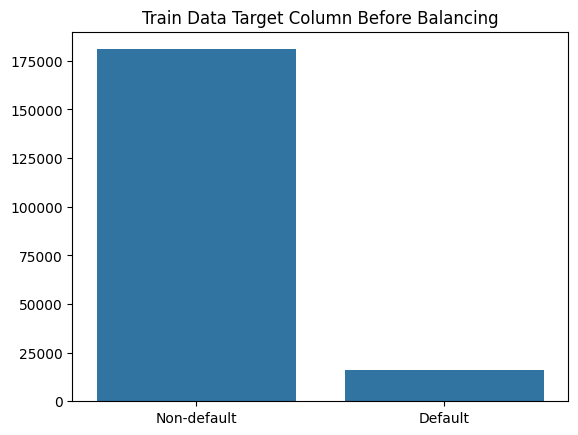

In [424]:
import matplotlib.pyplot as plt
import seaborn as sns

counts_train = y_train.value_counts()

sns.barplot(x=['Non-default', 'Default'], y=counts_train.values)
plt.title('Train Data Target Column Before Balancing')
plt.show()

In [425]:
print(f"Percentage of defaults in entire dataset: {df.TARGET.mean() * 100 :.2f}%")
print(f"Percentage of defaults in training dataset: {y_train.mean() * 100 :.2f}%")
print(f"Percentage of defaults in validation dataset: {y_val.mean() * 100 :.2f}%")
print(f"Percentage of defaults in test dataset: {y_test.mean() * 100 :.2f}%")

Percentage of defaults in entire dataset: 8.07%
Percentage of defaults in training dataset: 8.07%
Percentage of defaults in validation dataset: 8.07%
Percentage of defaults in test dataset: 8.07%


About 8% of borrowers in this dataset defaulted and about 92% didn't. Therefore, this dataset is highly imbalanced. If this were fed into a model, it could achieve 92% accuracy just by ignoring patterns and guessing non-default for everything, which would not be a useful model. In this dataset, the target column contains a 1 for borrowers who defaulted, and a 0 for borrowers who didn't.


### <u> Balance the dataset if the data is imbalanced

In [426]:
from imblearn.under_sampling import RandomUnderSampler

rus = RandomUnderSampler(sampling_strategy=0.33, random_state=RSEED)

X_train_final, y_train_final = rus.fit_resample(X_train_processed, y_train)

RandomUnderSampler will remove a large portion of the customers that didn't default. `sampling_strategy=0.33` makes the dataset have approximately 1 default for every 3 non-defaulters. I avoided complete 1:1 undersampling to preserve more information contained in the non-default portion of the data, which results in slightly better performance.

In [427]:
from sklearn.utils.class_weight import compute_class_weight 

# Calculate class weights using the 'balanced' heuristic
weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_final),
    y=y_train_final
)

class_weights = dict(enumerate(weights))

Class weights will make missing defaults increase the loss, which results in higher recall rates for the default class, which is important here.


### <u> Plot the balanced or imbalanced data

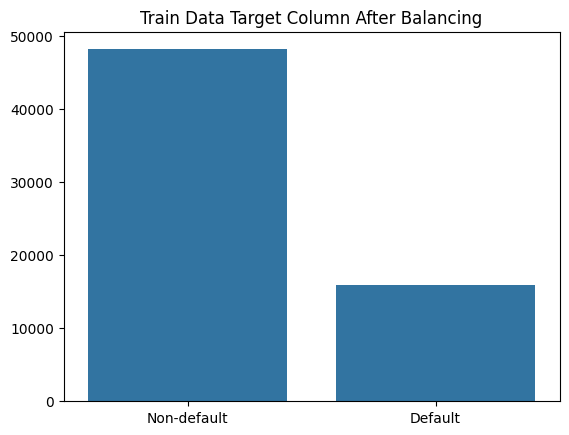

In [428]:
counts_train = y_train_final.value_counts()

sns.barplot(x=['Non-default', 'Default'], y=counts_train.values)
plt.title('Train Data Target Column After Balancing')
plt.show()

In [429]:
print(f"Percentage of defaults in new training dataset: {y_train_final.mean() * 100 :.2f}%")

Percentage of defaults in new training dataset: 24.81%



### <u> Model development and training

In [430]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

model = Sequential([
    Input(shape=(X_train_processed.shape[1],)),

    Dense(1, activation='sigmoid')
])


After experimenting with many architectures, a simple output neuron architecture performed equal or better than other architectures such as 1, 2 or 4 hidden neurons (with either `gelu` or `relu` as the activation function), or multiple layers with many neurons such as 256-128-64 and 128-64, different dropout amounts, and batch normalization. Therefore, I chose this simple model because it required less computation to get the same results.

In [431]:
from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer = Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)


I chose Adam as the optimizer with a learning rate of 0.001 because it is the industry standard. It performed slightly better than other learning rates such as 0.1 or 0.01.

In [432]:
model.summary()

Model: "sequential_19"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_37 (Dense)                │ (None, 1)              │           302 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 302 (1.18 KB)

 Trainable params: 302 (1.18 KB)

 Non-trainable params: 0 (0.00 B)

In [433]:
from tensorflow.keras.callbacks import EarlyStopping

callbacks = [
    EarlyStopping(
        monitor='val_auc', 
        mode='max', 
        patience=5, 
        restore_best_weights=True
    )
]

history = model.fit(
    X_train_final, y_train_final,
    epochs=75,
    batch_size=256,
    validation_data=(X_val_final, y_val),
    callbacks=callbacks,
    class_weight=class_weights,
    verbose=True
)

Epoch 1/75
251/251 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.5788 - auc: 0.6400 - loss: 0.6879 - val_accuracy: 0.6115 - val_auc: 0.7105 - val_loss: 0.6696
Epoch 2/75
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6536 - auc: 0.7319 - loss: 0.6107 - val_accuracy: 0.6530 - val_auc: 0.7362 - val_loss: 0.6329
Epoch 3/75
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6747 - auc: 0.7443 - loss: 0.5988 - val_accuracy: 0.6655 - val_auc: 0.7409 - val_loss: 0.6200
Epoch 4/75
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6808 - auc: 0.7471 - loss: 0.5956 - val_accuracy: 0.6696 - val_auc: 0.7426 - val_loss: 0.6147
Epoch 5/75
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6832 - auc: 0.7481 - loss: 0.5944 - val_accuracy: 0.6720 - val_auc: 0.7431 - val_loss: 0.6122
Epoch 6/75
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6844 - auc: 0.7485 - loss: 0.5939 - val_accuracy: 0.6729 - val_auc: 0.7435 - val_loss: 0.6110
Epoch 7/75
251/251 ━━━━━━━━━━━━━━━━━━━━ 

EarlyStopping helps prevents the model from computing more epochs than it has to, and can reduce overfitting by reverting to a step before overfitting began.


### <u> Calculate recall as a metric

In [434]:
# Run the model to get its predictions on the test set
y_pred_probs = model.predict(X_test_final)
THRESHOLD = 0.54
predictions_binary = (y_pred_probs > THRESHOLD).astype(int)

1922/1922 ━━━━━━━━━━━━━━━━━━━━ 1s 602us/step


Accuracy: 72.64%
              precision    recall  f1-score   support

           0       0.96      0.74      0.83     56538
           1       0.17      0.63      0.27      4965

    accuracy                           0.73     61503
   macro avg       0.56      0.68      0.55     61503
weighted avg       0.89      0.73      0.79     61503



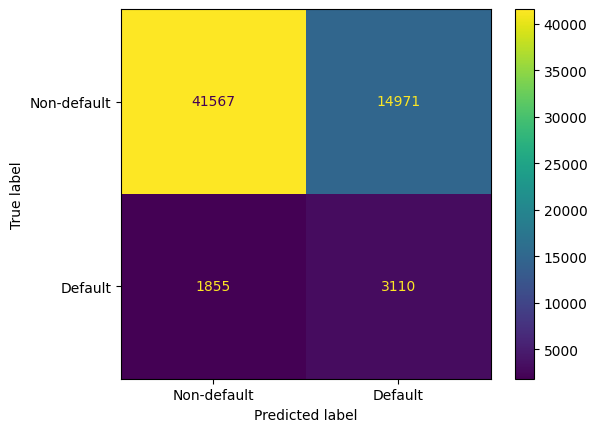

In [435]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score

accuracy = accuracy_score(y_test, predictions_binary)
print(f"Accuracy: {accuracy * 100 :.2f}%")
print(classification_report(y_test, predictions_binary))

conf_matrix = confusion_matrix(y_test, predictions_binary)
cm_display = ConfusionMatrixDisplay(confusion_matrix = conf_matrix, display_labels = ["Non-default", "Default"])
cm_display.plot()
plt.show()


### <u> Calculate the area under the receiver operating characteristics curve

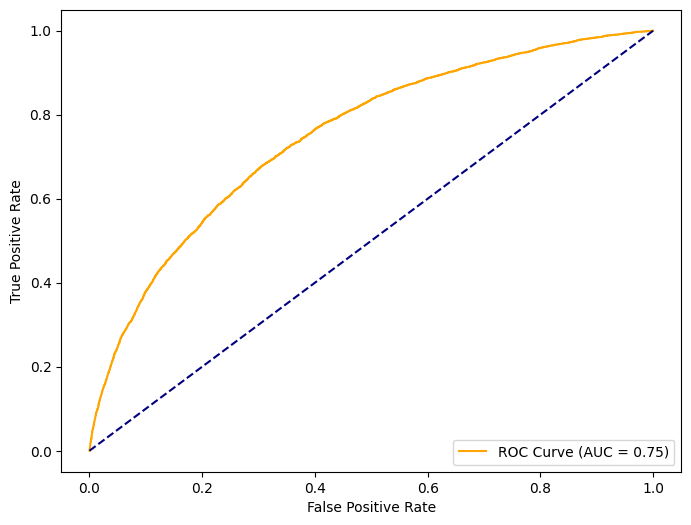

In [436]:
# ROC-AUC
from sklearn.metrics import roc_auc_score, roc_curve

auc_score = roc_auc_score(y_test, y_pred_probs)
false_pos_rate, true_pos_rate, thresholds = roc_curve(y_test, y_pred_probs)

plt.figure(figsize=(8, 6))
plt.plot(false_pos_rate, true_pos_rate, color='orange', label=f'ROC Curve (AUC = {auc_score :.2f})')
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.show()

The resulting model is able to identify approximately 63% (default recall 0.63) of borrowers who default in this specific test set. It creates a lot of false positives, only being correct 17% of the time that it predicts default (default precision 0.17). However, it is able to predict a fair percentage of defaulters. The trade-off is the large amount of false positives it creates, which can be tuned by adjusting the threshold. The usefulness of this would depend on the exact costs of a borrower defaulting vs falsely identifying a borrower as a probable defaulter. The AUC of 0.75 indicates a moderate ability to identify the risk of a borrower defaulting, well above the 0.5 score which would be no better than random guessing.

This model has likely reached its predictive limit or close, as experimenting with different hyperparameters (activation functions, different dataset balance ratios, turning on/off class weights, turning on/off batch normalization, different dropout percentages, different number of neurons and layers, different learning rates for Adam, AdamW with different weight decay rates, turning on/off Early Stopping and ReduceLROnPlateau, and different batch sizes) only ever gave a very minor performance improvement than this, often at the cost of more computation or complexity. 

Another project supports this by showing an AUC score of 0.74 with a neural network for the same dataset:
    
    https://www.kaggle.com/code/robimalco/home-credit-default-risk-pytorch-neural-network/log#:~:text=auc%3A%200.7414202648223795

To obtain higher performance, other types of models such as gradient boosted trees and using related datasets would likely be better, as is shown in similar projects that use the same dataset:
    
    https://www.kaggle.com/code/floser/binary-classification-credit-scoring/notebook#a11

    https://www.kaggle.com/code/hikmetsezen/micro-model-174-features-0-8-auc-on-home-credit